# Regresion Lineal

Lo que queremos hacer es crear nuetros datos de trabajo (30 empleados, donde `x` son sus **años de experiencia** e `y` es su **salario anual en miles de euros**), los guardamos en un archivo CSV y dibujaros en un gráfico de dispersión **(Scatter Plot)**

Si descargamos un dataset desconocido de internet, no sabemos que formula real hay detras. 

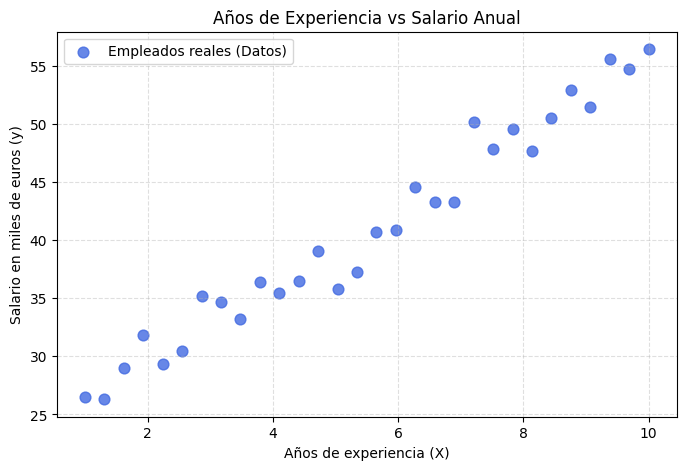

,experiencia_anios,salario_miles_eur
0,1.00,26.49
1,1.31,26.31
2,1.62,28.97
3,1.93,31.80
4,2.24,29.38


In [3]:
import os
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt

#Fijamos semillas aleatorias para que los 30 puntos salgan siempre iguales
np.random.seed(42)

#Creamos X: 30 empleados con experiencia repartida entre 1 y 10 años
#Creamos una lista de 30 números espaciados a la misma distancia empezando en 1 año
# en 1 años ( 1.0, 1.31, 1.62 ..)
X = np.linspace(1, 10, 30)

#Creamos y: Salario (miles de euros) = 3.5 * X + 22 + variación aleatoria (ruido)
#Genera 30 números al azar alrededor de 0 (unos positivos y otros negativos, con una desviación media de 2.0 que simulan 
# las diferencias naturales de sueldo entre empleados
ruido = np.random.normal(0, 2.0, size=30)
y = 3.5 * X + 22.0 + ruido

#Guardamos esta tabla dentro de un CSV dentro de data/
df = pd.DataFrame({
    "experiencia_anios": X.round(2),
    "salario_miles_eur": y.round(2)
})

df.to_csv("../data/salarios.csv", index=False)

#Dibujamos la nube de puntos (Scatter Plot)
plt.figure(figsize=(8,5))
plt.scatter(X, y, color="royalblue", s=60, alpha=0.8, label="Empleados reales (Datos)")
plt.title("Años de Experiencia vs Salario Anual")
plt.xlabel("Años de experiencia (X)")
plt.ylabel("Salario en miles de euros (y)")
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()

#Guardamos gráfico y mostramos los primeros 5 empleados de la tabla
plt.savefig("../reports/figures/01_scatter_datos.png", dpi=150, bbox_inches="tight")
plt.show()

df.head()

## Funciones Matematicas

`predecir(X, w, b)`: Dibuja una línea recta con cualquier inclunación (w) y una altura incial(b) que le digamos

`calcular_mse(y_real, y_pred)`: Nuestro "termómetro de error", que mide con un solo número qué tan lejos está esa línea recta de los 30 puntos azules reales

### Explicación de porque necesitamos este medidor de erorr (MSE)

Cuando nuestro algoritmo empieza a aprender, **no sabes cuánto valen `w` ni `b`, así que empieza probando a ciegas con `w = 0`y `b = 0`(prediciendo que los 30 empleados cobran 0 euros)

1. Mira la distancia vertical entre cada punto azul real (y) y la línea recta (y_pred): 
    - diferencia = y - y^

2. La eleva al cuadrado (** 2):

    Para que al restarse no de 0 de error y tambien porque al elevar al cuadrado castigas muchísimo más los fallos grandes.

3. Hace la media de los 3 empleados (`np.mean`)

    - MSE gigante -> la recta está lejísimos de los puntos
    - MSE pequeñito (cerca de 0) -> la recta pasa justo por el centro de los puntos

Recta inicial a ciegas -> w = 0.0, b =0.0
Error inicial (MSE):  1750.74 (Gigante porque la recta está en el suelo)


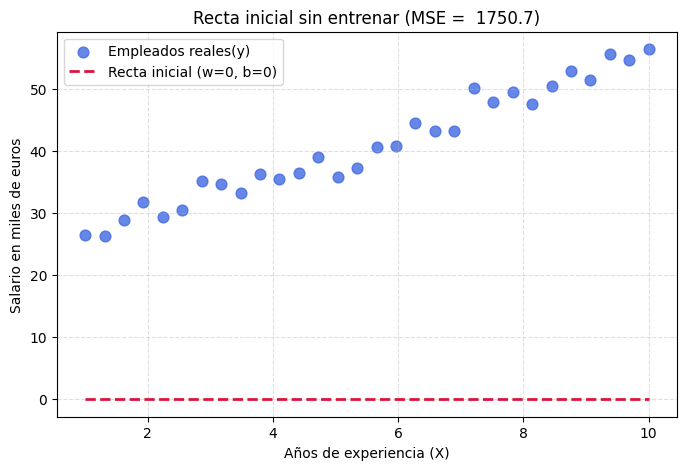

In [4]:
#Funcion de la recta: calcula el salario estimado (y_pred = w * X + b)
def predecir(X, w, b):

    #Formula de la regresion lineal, con el peso, el valor y el valor inicial
    return w * X  + b 

#Función de Error Cuadrático Medio(MSE): mide qué tan lejos está la recta de los puntos
def calcular_mse(y_real, y_pred):
    errores = y_real - y_pred
    return np.mean(errores ** 2)

#Probamos cómo empieza la máquina antes de entrenar (a ciegas: w = 0, b = 0)
w_inicial = 0.0
b_inicial = 0.0

y_pred_inicial = predecir(X, w_inicial, b_inicial)
error_inicial = calcular_mse(y, y_pred_inicial)

print(f"Recta inicial a ciegas -> w = {w_inicial}, b ={b_inicial}")
print(f"Error inicial (MSE): {error_inicial: .2f} (Gigante porque la recta está en el suelo)")

#Dibujamos cómo se ve esa recta en el suelo frente a los puntos reales
plt.figure(figsize=(8,5))
plt.scatter(X, y, color= "royalblue", s = 60, alpha=0.8, label="Empleados reales(y)")
plt.plot(X, y_pred_inicial, color="crimson", linewidth=2, linestyle="--", label="Recta inicial (w=0, b=0)")
plt.title(f"Recta inicial sin entrenar (MSE = {error_inicial: .1f})" )
plt.xlabel("Años de experiencia (X)")
plt.ylabel("Salario en miles de euros")
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()
plt.show()

## Descenso de Gradiente

La idea es justamente que esa línea roja suba y se incline ella sola hasta colocarse encima de los puntos azules y bajar el error de 1750 a casi 3.

Para que la máquina aprende sola , hace un bucle `for` repitiendo siempre 3 cosas:

1. Calcular las derivadas **(dw y db)**

    - db: Altura
        `db = -2 * np.mean(y - y_pred)`
        Mira cuánto nos falta girar la pendiente de la rect (multiplicando el error por los años X)
    
    -dw: Inclinación
        `dw = -2 * np.mean(X * (y - y_pred))`
        Mira cuánto nos falta girar la pendiente de la recta (multiplicando el error por los años X)

2. El tamaño del paso: `learning_rate` (Tasa de aprendizaje = `0.01` )

No podemos mover la recta de un salto gigante de golpe, porque nos pasaríamos de largo y el error rebotaría sin control. Por eso multiplicamos por un número pequeñito ( `learning_rate = 0.01` ) para acercarnos dando pasitos suaves y seguros

3. Las repeticiones: `epochs` (Épocas = `3000` intentos)

Como damos pasitos pequeños, metemos la actualización dentro de un bucle de `3000` vueltas (`epochs`):

In [5]:
def entrenar_descenso_gradiente(X, y, learning_rate=0.01, epochs=3000):
    #Empezamos a ciegas
    w = 0.0
    b = 0.0

    #Guardaremos el error de cada vuelta para dibujarlo en la proxima fase
    historial_mse = []

    #Bucle de aprendizaje (damos 3000 pasitos)
    for epoca in range(epochs):
        #Precedimos con la recta actual
        y_pred = predecir(X, w, b)

        #Medir el error actual y guardarlo
        mse = calcular_mse(y, y_pred)
        historial_mse.append(mse)

        #Calculamos la brújula (derivadas dw y db)
        dw = -2 * np.mean(X *(y - y_pred))
        db = -2 * np.mean(y - y_pred)

        #Dar un pasito para mejorar w y b
        w = w - learning_rate * dw
        b = b - learning_rate * db

        #Imprimimos el progreso cada 500 épocas para ver cómo aprende en vivo
        if epoca % 500 == 0:
            print(f"Época {epoca:4d} | MSE: {mse: 8.2f} | w: {w: .2f} | b: {b: .2f}")
    
    return w, b, historial_mse

#Ejecutamos el entrenamiento de nuestra máquina
w_final, b_final, historial_mse = entrenar_descenso_gradiente(X, y, learning_rate=0.01, epochs=3000)

print("-" * 55)
print(f"Entranmiento terminado")
print(f"Fórmula real secreta -> Subida (w) = 3.50 | Base (b) = 22.00")
print(f"Descubierto por NumPy -> Subida (w) = { w_final: .2f} | Base (b) = {b_final: .2f}")
print(f"Error final (MSE): {historial_mse[-1]: .2f} (bajó desde 1750.74)")

Época    0 | MSE:  1750.74 | w:  4.97 | b:  0.82
Época  500 | MSE:     4.88 | w:  3.76 | b:  19.57
Época 1000 | MSE:     2.81 | w:  3.35 | b:  22.37
Época 1500 | MSE:     2.76 | w:  3.28 | b:  22.79
Época 2000 | MSE:     2.76 | w:  3.28 | b:  22.86
Época 2500 | MSE:     2.76 | w:  3.27 | b:  22.87
-------------------------------------------------------
Entranmiento terminado
Fórmula real secreta -> Subida (w) = 3.50 | Base (b) = 22.00
Descubierto por NumPy -> Subida (w) =  3.27 | Base (b) =  22.87
Error final (MSE):  2.76 (bajó desde 1750.74)


Lo que mas se aproxima a nuestra regresión lineal es w = 3.27 y b = 22.87

## Visualizar cómo aprende la Máquina

02_curva_error_mse.png: Muestra cómo el error MSE cae en picado época tras época hasta quedarse plano en 2.76.

03_recta_ajustada.png: Dibuja los 30 puntos azules reales y encima la línea verde ganadora (w = 3.27, b = 22.87) que aprendió el algoritmo


### Importancia de estos dos gráficos

En Machine Learning, y Deep Learning, la **Curva de Error (Loss Curve)** es el electrocardiograma del modelo. Si vemos que la curva baja y se aplana entonces sabemos que el **learning_rate** es bueno y el modelo terminó de aprender.

El grafico de la **Recta Ajustada** es la demostración visual de que atraviesa los 30 empleados

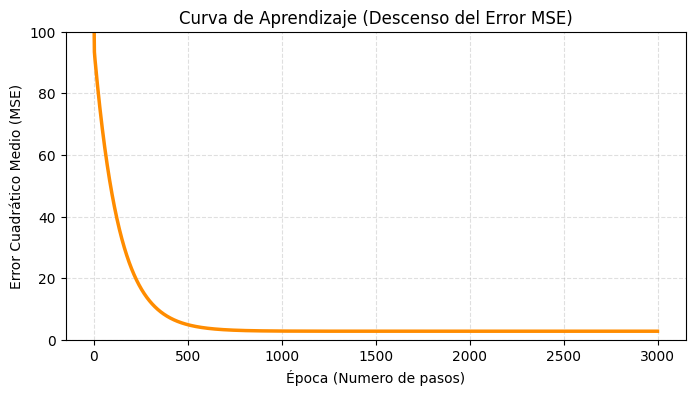

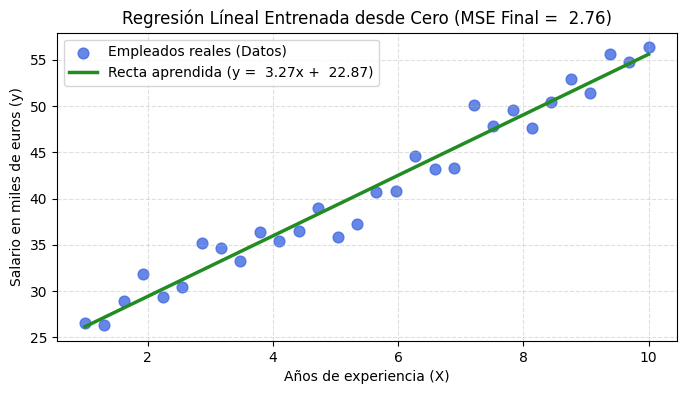

In [6]:
#Grafico 1: Curva de Aprendizaje

plt.figure(figsize=(8, 4))
plt.plot(historial_mse, color="darkorange", linewidth=2.5)
plt.title("Curva de Aprendizaje (Descenso del Error MSE)")
plt.xlabel("Época (Numero de pasos)")
plt.ylabel("Error Cuadrático Medio (MSE)")
plt.ylim(0,100) #Hacemos zoom para ver bien la curva después del primera bajón
plt.grid(True, linestyle="--", alpha=0.4)

plt.savefig("../reports/figures/02_curva_error_mse.png", dpi=150, bbox_inches="tight")
plt.show()

#Gráfico 2: Recta Final Aprendida vs Empleados reales
y_pred_final = predecir(X, w_final, b_final)

plt.figure(figsize=(8, 4))
plt.scatter(X, y, color="royalblue", s=60, alpha=0.8, label="Empleados reales (Datos)")
plt.plot(X, y_pred_final, color="forestgreen", linewidth=2.5, label=f"Recta aprendida (y = {w_final: .2f}x + {b_final: .2f})")
plt.title(f"Regresión Líneal Entrenada desde Cero (MSE Final = {historial_mse[-1]: .2f})")
plt.xlabel("Años de experiencia (X)")
plt.ylabel("Salario en miles de euros (y)")
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()

plt.savefig("../reports/figures/03_recta_ajustada.png", dpi=150, bbox_inches="tight")
plt.show()

## Clase LinearRegressionFromScratch 

Metemos las funciones que hemos hecho ( predecir(), entrenar_descenso_gradiente() )

La idea es hacer los mismos 3 pasos que `scikit-learn`. Creamos `fit()` y `.predict()`

In [7]:
class LinearRegressionFromScratch:
    def __init__(self, learning_rate=0.01, epochs=3000):
        #Guardamos la configuración inicial del modelo
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.w = 0.0
        self.b = 0.0
        self.historial_mse = []

    def fit(self, X, y):
        #Reiniciamos pesos antes de entrenar
        self.w = 0.0
        self.b = 0.0
        self.historial_mse = []

        #Bucle de Descenso de Gradiente
        for _ in range(self.epochs):
            y_pred = self.w * X + self.b
            mse = np.mean((y- y_pred) ** 2)
            self.historial_mse.append(mse)

            dw = -2 * np.mean(X * (y - y_pred))
            db = -2 * np.mean(y - y_pred)

            self.w -= self.learning_rate * dw
            self.b -= self.learning_rate * db

        return self

    def predict(self, X):
        #Formula de la recta con los pesos ya aprendidos
        return self.w * X + self.b

    
#Probamos nuestra propia librería como si fuera Scikit-learn
mi_modelo = LinearRegressionFromScratch(learning_rate=0.01, epochs=3000)
mi_modelo.fit(X,y)

#Predecimos cuánto debería cobrar alguien nuevo con 5 años y con 12 años de experiencia
nuevos_empleados = np.array([5.0, 12.0])
predicciones = mi_modelo.predict(nuevos_empleados)

print(f"Modelo Entrenado -> w = {mi_modelo.w: .4f} | b = {mi_modelo.b: .4f}")
print(f"Predicción para 5 años de experiencia: {predicciones[0]: .2f} mil euros")
print(f"Predicción para 12 años de experiencia: {predicciones[1]: .2f} mil euros")

Modelo Entrenado -> w =  3.2736 | b =  22.8689
Predicción para 5 años de experiencia:  39.24 mil euros
Predicción para 12 años de experiencia:  62.15 mil euros


## Coeficiente de Determinación desde 0

Queremos programar desde cero la nota R^2 para ponerle una nota del **0% al 100%**  a nuestra recta.

Tambien queremos entrenar el LinearRegression oficial de scikit-learn con los mismo 30 empleados **solo para comparar** y demostrar que le motor que hemos programado llega a la misma solución.

R^2 compara nuestra recta con un "modelo tonto" que siempre predice el sueldo medio de la empresa. (`np.mean(y)`)



In [9]:
from sklearn.linear_model import LinearRegression

#Programa desde cero la nota R^2 (de 0 a 1, donde 1 es perfecto)

def calcular_r2(y_real, y_pred):
    error_muestra_recta = np.sum((y_real - y_pred) ** 2)
    variacion_respecto_media = np.sum((y_real - np.mean(y_real)) ** 2)
    return 1 - (error_muestra_recta / variacion_respecto_media)

#Evaluamos nuestro modelo hecho 100% con NumPy
y_pred_numpy  = mi_modelo.predict(X)
mse_numpy = calcular_mse(y, y_pred_numpy)
r2_numpy = calcular_r2(y, y_pred_numpy)

#Entrenamos el LinearRegression oficial de Scikit-learn solo para comparar

#Necesitamos una tabla 2D de 30 filas x 1 columna, por eso usamos X.reshape((-1,1))

X_2d = X.reshape(-1, 1)
modelo_sklearn = LinearRegression()
modelo_sklearn.fit(X_2d, y)

y_pred_sklearn = modelo_sklearn.predict(X_2d)
mse_sklearn = calcular_mse(y, y_pred_sklearn)
r2_sklearn = calcular_r2(y, y_pred_sklearn)

#Comparativa cara a cara: Nuestro código vs Scikit-learn
comparativa = pd.DataFrame({
    "Implementación": ["Nuetra Regresión (100% NumPy)", "Scikit-learn Oficial"],
    "Pendiente(w)": [round(mi_modelo.w, 4), round(modelo_sklearn.coef_[0], 4)],
    "Base / Intercepto (b)": [round(mi_modelo.b, 4), round(modelo_sklearn.intercept_, 4)],
    "Error Final (MSE)": [round(mse_numpy, 4), round(mse_sklearn, 4)],
    "Nota R^2": [f"{r2_numpy * 100: .2f}%", f"{r2_sklearn * 100: .2f}%"]
})

comparativa

,Implementación,Pendiente(w),Base / Intercepto (b),Error Final (MSE),Nota R^2
0,Nuetra Regresión (100% NumPy),3.2736,22.8689,2.762,96.55%
1,Scikit-learn Oficial,3.2735,22.8692,2.762,96.55%


## Conclusiones Finales

1. **Precisión idéntica a `scikit-learn` (100% desde cero con NumPy):** Nuestro motor programado a mano logró exactamente el mismo error final (**`MSE = 2.762`**) y la misma nota de ajuste (**`R² = 96.55%`**) que el `LinearRegression` oficial de `scikit-learn`, descubriendo por sí solo la pendiente (`w = 3.2736`) y el sueldo base (`b = 22.8689`).
2. **Cómo aprende realmente una máquina bajo el capó:** Partiendo a ciegas desde el suelo (`w = 0, b = 0` con `MSE = 1750.74`), comprobamos cómo el **Descenso del Gradiente** utiliza las derivadas (`dw` y `db`) como brújula y el `learning_rate = 0.01` como tamaño de paso durante `3000` épocas para minimizar el error.
3. **Por qué varía `0.0001` en el cuarto decimal:** Mientras `scikit-learn` despeja una ecuación matricial directa (*Mínimos Cuadrados Ordinarios*), nuestro modelo se aproxima paso a paso mediante Descenso del Gradiente —el mismo principio de optimización sobre el que funcionan las Redes Neuronales y el Deep Learning moderno.